Among non-central census tracts with state/federal route exposure, what roadway attributes distinguish high-crash corridors from lower-crash corridors?

hypothesis：
In eastern and southeastern DC, high crash density may be partly associated with major state/federal route corridors passing through residential or majority-Black census tracts.

H1：state/federal route exposure 和 crash count 正相关
H0: state_federal_route_density 的系数 = 0
H1: state_federal_route_density 的系数 > 0

Level 1：Tract-level route exposure analysis

每个 census tract 还是一行，但你新增 state/federal route 变量：

state_federal_route_length_km
state_federal_route_density_km_per_km2
state_federal_route_share
mean_aadt_on_state_federal_routes
max_aadt_on_state_federal_routes
intersections_per_state_federal_route_km
signals_per_state_federal_route_km

然后回答：

Among tracts, does greater major-route exposure correspond to higher crash density?

Level 2：Route-buffer corridor analysis

把所有 state/federal routes 单独拉出来，做 50m 或 100m buffer。一个route可以穿过无数个census tracts

然后算：

crashes_within_100m_of_state_federal_route
/
state_federal_route_length_km

这个回答的是：

Major route corridors 本身是不是 crash-intensive？

这个比 tract-level crash density 更贴近你的问题。

是不是也要比较 buffer 内 crashes 和同一个 tract 里不靠近 route 的 crashes？

对，非常应该。这个比较很有价值。

你可以在每个 tract 里面分成两个区域：

Near-route zone: within 100m of state/federal route
Non-route zone: outside 100m buffer

=====================================================================

Table 1：tract_route_exposure_table
一行一个 tract：

GEOID
area_km2
crash_count
crash_density_km2
road_total_length_km
crash_per_road_km
state_federal_route_length_km
state_federal_route_density
state_federal_route_share
mean_aadt
max_aadt
intersection_density_km2
signal_density_km2
black_alone_share
hispanic_or_latino_share

这个用于 tract-level regression / random forest。

-------------------------------------------------

Table 2：tract_route_buffer_table

一行一个 tract-zone：

GEOID
zone_type: within_100m_route / outside_100m_route
crash_count
zone_area_km2
zone_road_length_km
crash_density_km2
crash_per_road_km

Table 2：tract_route_buffer_table

一行一个 tract-zone：

GEOID
zone_type: within_100m_route / outside_100m_route
crash_count
zone_area_km2
zone_road_length_km
crash_density_km2
crash_per_road_km

这个用于比较同一个 tract 内 route buffer vs non-buffer。

因为同一条 state/federal route 会穿过很多 tract，所以处理方式应该是：

把 route geometry clip 到每个 census tract 内，再计算每个 tract 内的 route length。

不要用整条 route 的总长度直接 assign 给所有 tract。



car accident 
-> %redisential by zoning
-> single family home vs high rise condo / apt
-> (commerical vs industrial) optional


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import geopandas as gpd
from shapely.geometry import Point

## Load Dataset

In [2]:
auto_claims_dc = pd.read_csv("../../../Data/auto_claims_dc.csv")

In [3]:
auto_claims_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11811 entries, 0 to 11810
Data columns (total 100 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   GEOID                          11811 non-null  int64  
 1   year                           11811 non-null  float64
 2   month                          11811 non-null  float64
 3   crash_count                    11811 non-null  int64  
 4   speeding_count                 11811 non-null  int64  
 5   total_vehicles                 11811 non-null  int64  
 6   fatal_driver                   11811 non-null  int64  
 7   fatal_pedestrian               11811 non-null  int64  
 8   fatal_bicyclist                11811 non-null  int64  
 9   major_inj_driver               11811 non-null  int64  
 10  major_inj_ped                  11811 non-null  int64  
 11  major_inj_bike                 11811 non-null  int64  
 12  weekend_crash                  11811 non-null

## Convert monthly panel to tract-level table

In [4]:
df = auto_claims_dc.copy()

# Convert GEOID to string and preserve 11-digit census tract format
auto_claims_dc["GEOID"] = auto_claims_dc["GEOID"].astype(str).str.zfill(11)

# Convert year and month to integer
df["year"] = df["year"].astype(int)
df["month"] = df["month"].astype(int)

# Add year-month period variable
df["year_month"] = pd.to_datetime(
    df[["year", "month"]].assign(day=1)
).dt.to_period("M")

In [5]:
tract_df = (
    df
    .groupby("GEOID", as_index=False)
    .agg(
        # Crash outcomes
        total_crashes=("crash_count", "sum"),
        avg_monthly_crashes=("crash_count", "mean"),
        total_speeding=("speeding_count", "sum"),
        total_vehicles=("total_vehicles", "sum"),
        night_crashes=("night_crash", "sum"),
        weekend_crashes=("weekend_crash", "sum"),
        rush_hour_crashes=("rush_hour_crash", "sum"),

        # Time coverage
        n_months=("year_month", "nunique"),

        # Area / population
        area_km2=("area_km2", "first"),
        total_population=("total_population", "first"),

        # Demographics
        white_alone_share=("white_alone_share", "first"),
        black_alone_share=("black_alone_share", "first"),
        asian_alone_share=("asian_alone_share", "first"),
        hispanic_share=("hispanic_share", "first"),
        two_or_more_races_share=("two_or_more_races_share", "first"),
        other_race_share=("other_race_share", "first"),

        # Traffic signal / intersection features
        traffic_ct=("traffic_ct", "first"),
        traffic_intersection_ct=("traffic_intersection_ct", "first"),
        lpi_ct=("lpi_ct", "first"),
        aps_installed_ct=("aps_installed_ct", "first"),

        # Roadway features
        road_segment_count=("road_segment_count", "first"),
        road_total_length_m=("road_total_length_m", "first"),
        mean_aadt=("mean_aadt", "first"),
        mean_iri=("mean_iri", "first"),
        mean_speedlimit_ob=("mean_speedlimit_ob", "first"),

        # Existing roadway design controls
        high_speed_ratio=("high_speed_ratio", "first"),
        bike_lane_ratio=("bike_lane_ratio", "first"),
        sidewalk_ib_ratio=("sidewalk_ib_ratio", "first"),
        sidewalk_ob_ratio=("sidewalk_ob_ratio", "first"),

        # Additional roadway design controls for Model 4
        bus_lane_ratio=("bus_lane_ratio", "first"), # bus_lane_ratio: road capacity / number of lanes
        mean_pci_score=("mean_pci_score", "first"), # mean_pci_score: pavement condition
        avg_travel_lanes=("avg_travel_lanes", "first"), # avg_travel_lanes: road capacity / number of lanes
        parking_lane_ratio=("parking_lane_ratio", "first"), # parking_lane_ratio: share of road segments with parking lane
        avg_cross_section_width=("avg_cross_section_width", "first"), # Average total street/roadway cross-section width of road segments within each census tract.
        vertical_deflection_ratio=("vertical_deflection_ratio", "first") # vertical_deflection_ratio: traffic calming features, like speed humps / raised crosswalks
    )
)

In [6]:
# Tract-specific observed years
tract_df["n_years"] = tract_df["n_months"] / 12

# Road length in km
tract_df["road_length_km"] = tract_df["road_total_length_m"] / 1000

# Cumulative crash density over observed period
tract_df["crash_density_km2"] = (
    tract_df["total_crashes"] / tract_df["area_km2"]
)

# Average annual crash density
tract_df["avg_annual_crash_density"] = (
    tract_df["total_crashes"] / tract_df["n_years"] / tract_df["area_km2"]
)

# Crashes per road km
tract_df["crashes_per_road_km"] = (
    tract_df["total_crashes"] / tract_df["road_length_km"]
)

# Crashes per 10K population
tract_df["crashes_per_10k_pop"] = (
    tract_df["total_crashes"] / tract_df["total_population"] * 10000
)

# Road density
tract_df["road_density_km_per_km2"] = (
    tract_df["road_length_km"] / tract_df["area_km2"]
)

# Road segment density
tract_df["road_segment_density_km2"] = (
    tract_df["road_segment_count"] / tract_df["area_km2"]
)

# Traffic signal density
tract_df["signal_density_km2"] = (
    tract_df["traffic_ct"] / tract_df["area_km2"]
)

# Traffic intersection density
tract_df["intersection_density_km2"] = (
    tract_df["traffic_intersection_ct"] / tract_df["area_km2"]
)

# Time-of-crash ratios
tract_df["weekend_ratio"] = (
    tract_df["weekend_crashes"] / tract_df["total_crashes"]
)

tract_df["night_ratio"] = (
    tract_df["night_crashes"] / tract_df["total_crashes"]
)

tract_df["rush_hour_ratio"] = (
    tract_df["rush_hour_crashes"] / tract_df["total_crashes"]
)

# Negative Binomial exposure offset
tract_df["log_exposure_offset"] = np.log(
    tract_df["area_km2"] * tract_df["n_years"]
)

# Clean infinite values caused by division by zero
tract_df = tract_df.replace([np.inf, -np.inf], np.nan)

In [7]:
stact_check_cols = [
    "area_km2",
    "total_population",
    "black_alone_share",
    "hispanic_share",
    "road_total_length_m",
    "mean_aadt",
    "bike_lane_ratio",
    "bus_lane_ratio",
    "parking_lane_ratio",
    "traffic_ct",
    "traffic_intersection_ct"
]

df.groupby("GEOID")[stact_check_cols].nunique().max().sort_values(ascending=False)

area_km2                   1
total_population           1
black_alone_share          1
hispanic_share             1
road_total_length_m        1
mean_aadt                  1
bike_lane_ratio            1
bus_lane_ratio             1
parking_lane_ratio         1
traffic_ct                 1
traffic_intersection_ct    1
dtype: int64

In [8]:
static_check_cols = [
    "area_km2",
    "total_population",
    "black_alone_share",
    "hispanic_share",
    "road_total_length_m",
    "mean_aadt",
    "bike_lane_ratio",
    "bus_lane_ratio",
    "parking_lane_ratio",
    "traffic_ct",
    "traffic_intersection_ct"
]

df.groupby("GEOID")[static_check_cols].nunique().max().sort_values(ascending=False)

area_km2                   1
total_population           1
black_alone_share          1
hispanic_share             1
road_total_length_m        1
mean_aadt                  1
bike_lane_ratio            1
bus_lane_ratio             1
parking_lane_ratio         1
traffic_ct                 1
traffic_intersection_ct    1
dtype: int64

In [9]:
print(tract_df.shape)

print(tract_df["GEOID"].nunique())

print(tract_df["GEOID"].duplicated().sum())

(206, 50)
206
0


In [10]:
tract_df[[
    "total_crashes",
    "n_months",
    "n_years",
    "area_km2",
    "crash_density_km2",
    "avg_annual_crash_density",
    "road_length_km",
    "crashes_per_road_km"
]].describe()

,total_crashes,n_months,n_years,area_km2,crash_density_km2,avg_annual_crash_density,road_length_km,crashes_per_road_km
count,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000
mean,507.616505,57.334951,4.777913,0.768525,992.451062,202.999233,16.756430,35.666209
std,424.006113,6.125472,0.510456,0.855192,754.891200,150.002667,13.564695,24.751921
min,19.000000,16.000000,1.333333,0.093419,16.009515,4.002379,3.768258,1.314087
25%,224.250000,57.000000,4.750000,0.290739,448.928425,93.276789,8.418769,17.561840
50%,411.500000,60.000000,5.000000,0.507151,823.890778,167.518858,12.601275,30.840785
75%,611.750000,60.000000,5.000000,0.907396,1451.926479,291.327289,21.203759,47.466742
max,2984.000000,60.000000,5.000000,6.514228,4543.843254,908.768651,119.900341,213.952690


In [11]:
tract_df["n_months"].describe()

count    206.000000
mean      57.334951
std        6.125472
min       16.000000
25%       57.000000
50%       60.000000
75%       60.000000
max       60.000000
Name: n_months, dtype: float64

Most tracts have close to 5 years data, only a few tracts miss a lot months

In [12]:
tract_df["n_months"].value_counts().sort_index()

n_months
16      1
28      1
29      1
33      1
34      1
36      1
41      1
43      3
44      1
47      1
48      2
49      2
50      2
52      3
53      3
54      4
55      4
56      6
57     15
58      7
59     28
60    118
Name: count, dtype: int64

In [13]:
tract_df.head()

,GEOID,total_crashes,avg_monthly_crashes,total_speeding,total_vehicles,night_crashes,weekend_crashes,rush_hour_crashes,n_months,area_km2,...,crashes_per_road_km,crashes_per_10k_pop,road_density_km_per_km2,road_segment_density_km2,signal_density_km2,intersection_density_km2,weekend_ratio,night_ratio,rush_hour_ratio,log_exposure_offset
0,11001000101,104,2.418605,0,193,35,21,32,43,0.199776,...,14.346707,880.609653,36.285893,180.201826,NaN,NaN,0.201923,0.336538,0.307692,-0.334265
1,11001000102,782,13.033333,6,1467,296,228,218,60,1.706484,...,26.150527,2558.900524,17.523631,87.314033,4.688002,4.688002,0.291560,0.378517,0.278772,2.143873
2,11001000201,79,1.795455,2,148,20,15,26,44,0.505004,...,11.573773,278.659612,13.516284,75.246929,3.960365,3.960365,0.189873,0.253165,0.329114,0.616094
3,11001000202,902,15.033333,10,1732,325,254,255,60,0.776435,...,38.682410,2275.479314,30.032253,181.599232,21.894943,20.607005,0.281596,0.360310,0.282705,1.356396
4,11001000300,274,4.644068,1,531,85,54,82,59,1.042156,...,13.470979,483.330393,19.517252,142.013288,1.919098,1.919098,0.197080,0.310219,0.299270,1.633922


#### route_tract is a route-piece-level table.
#### Each row represents one clipped major route segment within one census tract.
#### The overlay step assigns each route piece to a GEOID and calculates its length.
#### Next, we aggregate these route pieces by GEOID to obtain tract-level major route exposure.

major_routes
= 所有 FHWA 1,2,3,4 的 road lines

+ tract_poly
= 所有 census tract polygons

↓ overlay

route_tract
= major routes 被 tract boundary 切开后的小段
= 每一行有 GEOID + route label + clipped length

↓ groupby GEOID

route_exposure_df
= 每个 tract 里面 major route 总长度
= 每个 tract 里面 major route segment count

↓ merge 回 tract_df

tract_route_df
= crash + demographics + road variables + major route exposure

In [14]:
# Base tract-level table
# tract_df already exists

# Census tract geometry
acs_demographics = gpd.read_file(
    "../../../Data/ACS_5-Year_Demographic_Characteristics_of_DC_Census_Tracts/ACS_5-Year_Demographic_Characteristics_of_DC_Census_Tracts.shp"
)

# Road segment geometry / AADT / roadway attributes
roadwayB_geo = gpd.read_file(
    "../../../Data/Roadway_Block.geojson"
)

# Road functional hierarchy / route class
roadwayFC = gpd.read_file(
    "../../../Data/Roadway_Functional_Classification.geojson"
)

In [15]:
roadwayFC["FHWAFUNCTIONALCLASS"].value_counts(dropna=False).sort_index()

FHWAFUNCTIONALCLASS
1      23
2      31
3    1207
4    2074
5    1849
6     166
7    8485
Name: count, dtype: int64

In [16]:
roadwayFC["DCFUNCTIONALCLASS"].value_counts(dropna=False).sort_index()

DCFUNCTIONALCLASS
11      23
12      31
14    1208
16    2074
17    1849
18     166
19    8484
Name: count, dtype: int64

In [17]:
# Roadway_Functional_Classification: Data cleaning

fhwa_class_map = {
    -1: "Unknown",
    1: "Interstate",
    2: "Principal Arterial - Other Freeways or Expressways",
    3: "Principal Arterial - Other",
    4: "Minor Arterial",
    5: "Major Collector",
    6: "Minor Collector",
    7: "Local"
}

roadwayFC["FHWAFUNCTIONALCLASS_clean"] = (
    roadwayFC["FHWAFUNCTIONALCLASS"]
    .replace(0, pd.NA)
    .fillna(-1)
    .astype(int)
)

roadwayFC["fhwa_class_label"] = (
    roadwayFC["FHWAFUNCTIONALCLASS_clean"].map(fhwa_class_map)
)

In [18]:
roadwayFC["fhwa_class_label"].value_counts(dropna=False)

fhwa_class_label
Local                                                 8485
Minor Arterial                                        2074
Major Collector                                       1849
Principal Arterial - Other                            1207
Minor Collector                                        166
Principal Arterial - Other Freeways or Expressways      31
Interstate                                              23
Name: count, dtype: int64

In [19]:
# Define major route exposure
major_fhwa_codes = [1, 2, 3, 4]

roadwayFC["is_major_route"] = (
    roadwayFC["FHWAFUNCTIONALCLASS_clean"].isin(major_fhwa_codes)
)

roadwayFC.groupby("fhwa_class_label")["is_major_route"].value_counts()

fhwa_class_label                                    is_major_route
Interstate                                          True                23
Local                                               False             8485
Major Collector                                     False             1849
Minor Arterial                                      True              2074
Minor Collector                                     False              166
Principal Arterial - Other                          True              1207
Principal Arterial - Other Freeways or Expressways  True                31
Name: count, dtype: int64

acs_demographics polygon + roadwayFC line
→ spatial overlay
→ route_exposure_df with GEOID

tract_df + route_exposure_df
→ regular merge by GEOID

In [20]:
# Step 1: Prepare tract polygon

# =============================
# EPSG:4326  = WGS84 geographic coordinate system
#              Coordinates are longitude / latitude
#              Unit = degree
#              Good for storing GPS-style locations and web data exchange
#              Not good for length, area, or 100m buffer calculations

# EPSG:26918 = NAD83 / UTM Zone 18N projected coordinate system
#              Coordinates are easting / northing
#              Unit = meter
#              Good for Washington, DC / DMV area
#              Good for road length, area, distance, and buffer calculations

# EPSG:3926  = Not a CRS you should use for this DC project
#              EPSG:3926 is a coordinate transformation related to Slovenia,
#              not a projected CRS for Washington, DC
# =============================

# =============================
# CRS notes:
# EPSG:4326 uses longitude/latitude in degrees.
# EPSG:26918 uses meters and is appropriate for Washington, DC.
# For this analysis, convert geometries to EPSG:26918 before calculating
# route length, area, distance, or 100-meter buffers.
# =============================

# Raw / web-style spatial data
source_crs = "EPSG:4326"

# Measurement CRS for DC route length / area
target_crs = "EPSG:26918"

# Census tract polygon from ACS layer
tract_poly = acs_demographics[["GEOID", "geometry"]].copy()
tract_poly["GEOID"] = tract_poly["GEOID"].astype(str).str.zfill(11)

# Convert to projected CRS for length calculation
tract_poly = tract_poly.to_crs(target_crs)
roadwayFC = roadwayFC.to_crs(target_crs)

# Keep only major routes
major_routes = roadwayFC[roadwayFC["is_major_route"]].copy()

# Keep only useful columns to avoid messy overlay output
keep_cols = [
    "OBJECTID",
    "BLOCKKEY",
    "ROUTENAME",
    "FHWAFUNCTIONALCLASS_clean",
    "fhwa_class_label",
    "is_major_route",
    "geometry"
]

# Keep only columns that actually exist
keep_cols = [c for c in keep_cols if c in major_routes.columns]
 
major_routes = major_routes[keep_cols].copy()

In [21]:
# Step 2: Spatial overlay
# Cut major route lines by census tract polygons

route_tract = gpd.overlay(
    major_routes,
    tract_poly,
    how="intersection",
    keep_geom_type=True
)

# Calculate route length inside each tract
route_tract["major_route_length_km"] = (
    route_tract.geometry.length / 1000
)

route_tract.head()

,OBJECTID,BLOCKKEY,ROUTENAME,FHWAFUNCTIONALCLASS_clean,fhwa_class_label,is_major_route,GEOID,geometry,major_route_length_km
0,4381891,5aac8954155e7e355a0b7736cdd5dad5,7TH ST NW,3,Principal Arterial - Other,True,11001005802,"LINESTRING Z (324669.606 4307856.828 0, 324669...",0.000355
1,4381891,5aac8954155e7e355a0b7736cdd5dad5,7TH ST NW,3,Principal Arterial - Other,True,11001004703,"LINESTRING Z (324670.407 4307903.407 0, 324670...",0.000013
2,4381891,5aac8954155e7e355a0b7736cdd5dad5,7TH ST NW,3,Principal Arterial - Other,True,11001004702,"LINESTRING Z (324669.612 4307857.183 0, 324669...",0.046230
3,4381892,b6cf7c4c7dd2c9f1cd2088a004f5b98c,GEORGIA AVE NW,3,Principal Arterial - Other,True,11001003400,"MULTILINESTRING Z ((324712.977 4309842.251 0, ...",0.045104
4,4381892,b6cf7c4c7dd2c9f1cd2088a004f5b98c,GEORGIA AVE NW,3,Principal Arterial - Other,True,11001003500,"MULTILINESTRING Z ((324709.778 4309880.867 0, ...",0.063432


In [22]:
route_tract.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 5066 entries, 0 to 5065
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   OBJECTID                   5066 non-null   int32   
 1   BLOCKKEY                   5066 non-null   object  
 2   ROUTENAME                  5066 non-null   object  
 3   FHWAFUNCTIONALCLASS_clean  5066 non-null   int64   
 4   fhwa_class_label           5066 non-null   object  
 5   is_major_route             5066 non-null   bool    
 6   GEOID                      5066 non-null   object  
 7   geometry                   5066 non-null   geometry
 8   major_route_length_km      5066 non-null   float64 
dtypes: bool(1), float64(1), geometry(1), int32(1), int64(1), object(4)
memory usage: 301.9+ KB


1 row = 1 route piece inside 1 census tract

5066 route pieces total

GEOID 11001004702:
0.046 km + 0.063 km + 0.120 km + ...
= total major_route_length_km for this tract

In [23]:
route_tract["major_route_length_km"].describe()

count    5.066000e+03
mean     9.612721e-02
std      1.495407e-01
min      2.614362e-08
25%      2.700693e-02
50%      6.736200e-02
75%      1.143202e-01
max      2.480585e+00
Name: major_route_length_km, dtype: float64

The minimum major route length (km) is 0.00000002614362 km (2.614362e-08) = 0.00002614362 meters. Filter out those major route if their length is less than 1 meter(s)

In [24]:
(route_tract["major_route_length_km"] < 0.005).sum()

542

In [25]:
for threshold in [0.001, 0.005, 0.01]:
    n = (route_tract["major_route_length_km"] < threshold).sum()
    pct = n / len(route_tract) * 100
    print(f"< {threshold} km: {n} pieces ({pct:.1f}%)")

< 0.001 km: 440 pieces (8.7%)
< 0.005 km: 542 pieces (10.7%)
< 0.01 km: 708 pieces (14.0%)


In [26]:
sliver_threshold_km = 0.001 # 1 meter

route_tract_clean = route_tract[
    route_tract["major_route_length_km"] >= sliver_threshold_km
].copy()

In [27]:
route_tract_clean_5m = route_tract[
    route_tract["major_route_length_km"] >= 0.005
]

In [28]:
id_col = "BLOCKKEY" if "BLOCKKEY" in route_tract.columns else "OBJECTID"

route_exposure_df = (
    route_tract_clean
    .groupby("GEOID", as_index=False)
    .agg(
        major_route_segment_ct=(id_col, "nunique"),
        major_route_length_km=("major_route_length_km", "sum")
    )
)

route_exposure_df.head()

,GEOID,major_route_segment_ct,major_route_length_km
0,11001000101,7,1.634177
1,11001000102,54,5.288012
2,11001000201,4,0.305738
3,11001000202,36,3.798265
4,11001000300,10,0.810018


In [29]:
route_exposure_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   GEOID                   205 non-null    object 
 1   major_route_segment_ct  205 non-null    int64  
 2   major_route_length_km   205 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 4.9+ KB


There is 1 tract that does not have a qualifying FHWA 1-4 major route.

In [30]:
# Make sure GEOID format matches
tract_df["GEOID"] = tract_df["GEOID"].astype(str).str.zfill(11)
route_exposure_df["GEOID"]=route_exposure_df["GEOID"].astype(str).str.zfill(11)

# Make route exposure back to tract-level dataset
tract_route_df = tract_df.merge(
    route_exposure_df,
    on="GEOID",
    how="left"
)

# Tracts without major routes should be 0
tract_route_df[["major_route_segment_ct", "major_route_length_km"]] = (
    tract_route_df[["major_route_segment_ct", "major_route_length_km"]].fillna(0)
)

tract_route_df.shape

(206, 52)

In [31]:
tract_route_df["major_route_density_km_per_km2"] = (
    tract_route_df["major_route_length_km"] / tract_route_df["area_km2"]
)

tract_route_df["major_route_share"] = np.where(
    tract_route_df["road_length_km"] > 0,
    tract_route_df["major_route_length_km"] / tract_route_df["road_length_km"],
    np.nan
)

In [32]:
# Define route-exposed tracts
# 0.1 km = 100 meters of FHWA 1-4 major route inside the tract

min_route_exposure_km = 0.1

tract_route_df["route_exposed"] = (
    tract_route_df["major_route_length_km"] > min_route_exposure_km
)

tract_route_df["route_exposed"].value_counts()

route_exposed
True     205
False      1
Name: count, dtype: int64

In [33]:
tract_route_df.head()

,GEOID,total_crashes,avg_monthly_crashes,total_speeding,total_vehicles,night_crashes,weekend_crashes,rush_hour_crashes,n_months,area_km2,...,intersection_density_km2,weekend_ratio,night_ratio,rush_hour_ratio,log_exposure_offset,major_route_segment_ct,major_route_length_km,major_route_density_km_per_km2,major_route_share,route_exposed
0,11001000101,104,2.418605,0,193,35,21,32,43,0.199776,...,NaN,0.201923,0.336538,0.307692,-0.334265,7.0,1.634177,8.180048,0.225433,True
1,11001000102,782,13.033333,6,1467,296,228,218,60,1.706484,...,4.688002,0.291560,0.378517,0.278772,2.143873,54.0,5.288012,3.098776,0.176834,True
2,11001000201,79,1.795455,2,148,20,15,26,44,0.505004,...,3.960365,0.189873,0.253165,0.329114,0.616094,4.0,0.305738,0.605417,0.044792,True
3,11001000202,902,15.033333,10,1732,325,254,255,60,0.776435,...,20.607005,0.281596,0.360310,0.282705,1.356396,36.0,3.798265,4.891929,0.162889,True
4,11001000300,274,4.644068,1,531,85,54,82,59,1.042156,...,1.919098,0.197080,0.310219,0.299270,1.633922,10.0,0.810018,0.777252,0.039824,True


In [51]:
tract_route_df.to_csv(
    "../../../Data/tract_route_exposure_df.csv",
    index=False
)

In [52]:
tract_route_df.shape

(206, 55)

In [53]:
tract_route_df["GEOID"].nunique()

206

In [37]:
tract_route_df[[
    "major_route_segment_ct",
    "major_route_length_km",
    "major_route_density_km_per_km2",
    "major_route_share"
]].describe()

,major_route_segment_ct,major_route_length_km,major_route_density_km_per_km2,major_route_share
count,206.000000,206.000000,206.000000,206.000000
mean,22.456311,2.363835,4.006292,0.142449
std,19.403181,3.265024,2.932716,0.080534
min,0.000000,0.000000,0.000000,0.000000
25%,12.000000,0.990293,1.844783,0.091019
50%,18.000000,1.601842,3.235237,0.133859
75%,27.000000,2.769095,5.309587,0.179087
max,200.000000,41.097650,14.750946,0.534575


In [38]:
tract_route_df[[
    "GEOID",
    "total_crashes",
    "avg_annual_crash_density",
    "road_length_km",
    "major_route_length_km",
    "major_route_density_km_per_km2",
    "major_route_share",
    "black_alone_share",
    "hispanic_share"
]].sort_values(
    "major_route_length_km",
    ascending=False
).head(20)

,GEOID,total_crashes,avg_annual_crash_density,road_length_km,major_route_length_km,major_route_density_km_per_km2,major_route_share,black_alone_share,hispanic_share
205,11001980000,2804,86.088482,119.900341,41.097650,6.308906,0.342765,0.000000,0.000000
199,11001010700,1844,413.643970,23.492604,11.667947,13.086702,0.496665,0.037015,0.138956
194,11001010400,1416,108.822918,53.171988,9.478625,3.642273,0.178264,0.878788,0.020961
190,11001010100,1419,489.960810,15.983133,8.544191,14.750946,0.534575,0.107559,0.128244
204,11001011100,2984,104.359528,68.535952,8.263826,1.445055,0.120577,0.737011,0.145236
192,11001010202,1787,334.178598,37.597572,7.787039,7.281090,0.207115,0.308025,0.085759
114,11001007401,1458,241.168725,53.195617,6.906684,5.712196,0.129836,0.941015,0.012346
12,11001000802,215,26.343278,23.257995,6.565739,3.888318,0.282300,0.106824,0.102041
97,11001005802,1309,383.596488,17.313451,6.410274,9.392509,0.370248,0.119318,0.193182
21,11001001100,621,74.076283,39.872477,6.045384,3.605633,0.151618,0.127551,0.057010


avg_annual_crash_density refers to avg_annual_crash_density's 75th percentile.

In [39]:
# Define high-crash group in route-exposed tracts

route_tracts = tract_route_df[
    tract_route_df["route_exposed"]
].copy()

q90 = route_tracts["avg_annual_crash_density"].quantile(0.90)

route_tracts["high_crash_route_tract"] = (
    route_tracts["avg_annual_crash_density"] >= q90
).astype(int)

route_tracts["high_crash_route_tract"].value_counts()

high_crash_route_tract
0    184
1     21
Name: count, dtype: int64

52 high-crash route tracts basically are the top 25% crash density.

In [40]:
route_tracts.info()

<class 'pandas.core.frame.DataFrame'>
Index: 205 entries, 0 to 205
Data columns (total 56 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   GEOID                           205 non-null    object 
 1   total_crashes                   205 non-null    int64  
 2   avg_monthly_crashes             205 non-null    float64
 3   total_speeding                  205 non-null    int64  
 4   total_vehicles                  205 non-null    int64  
 5   night_crashes                   205 non-null    int64  
 6   weekend_crashes                 205 non-null    int64  
 7   rush_hour_crashes               205 non-null    int64  
 8   n_months                        205 non-null    int64  
 9   area_km2                        205 non-null    float64
 10  total_population                205 non-null    int64  
 11  white_alone_share               205 non-null    float64
 12  black_alone_share               205 non-n

# EDA

In [41]:
fig = px.scatter(
    route_tracts,
    x="major_route_density_km_per_km2",
    y="avg_annual_crash_density",
    color="black_alone_share",
    size="major_route_length_km",
    trendline="ols",
    trendline_scope="overall",
    opacity=0.7,
    hover_data=[
        "GEOID",
        "total_crashes",
        "major_route_length_km",
        "major_route_share",
        "black_alone_share",
        "hispanic_share",
        "asian_alone_share",
        "white_alone_share",
        "two_or_more_races_share",
        "other_race_share",
        "high_crash_route_tract"
    ],
    labels={
        "major_route_density_km_per_km2": "Major route density (km per km²)",
        "avg_annual_crash_density": "Average annual crash density",
        "black_alone_share": "Black alone share",
        "major_route_length_km": "Major route length (km)"
    },
    title="Major Route Density vs. Crash Density, Colored by Black Share"
)

fig.update_layout(width=950, height=650)
fig.show()

NameError: name 'px' is not defined

In [ ]:
"demo_highlight" in route_tracts.columns

In [42]:
race_cols = {
    "White": "white_alone_share",
    "Black": "black_alone_share",
    "Hispanic": "hispanic_share",
    "Asian": "asian_alone_share",
    "Two or More": "two_or_more_races_share",
    "Other": "other_race_share"
}

race_df = 

SyntaxError: invalid syntax (1391220852.py, line 10)

In [43]:
import plotly.express as px

fig = px.scatter(
    route_tracts,
    x="major_route_density_km_per_km2",
    y="avg_annual_crash_density",
    color="demo_highlight",
    trendline="ols",
    trendline_scope="overall",
    opacity=0.65,
    title="major_route_density_km_per_km2 vs. avg_annual_crash_density"
)

fig.show()

ValueError: Value of 'color' is not the name of a column in 'data_frame'. Expected one of ['GEOID', 'total_crashes', 'avg_monthly_crashes', 'total_speeding', 'total_vehicles', 'night_crashes', 'weekend_crashes', 'rush_hour_crashes', 'n_months', 'area_km2', 'total_population', 'white_alone_share', 'black_alone_share', 'asian_alone_share', 'hispanic_share', 'two_or_more_races_share', 'other_race_share', 'traffic_ct', 'traffic_intersection_ct', 'lpi_ct', 'aps_installed_ct', 'road_segment_count', 'road_total_length_m', 'mean_aadt', 'mean_iri', 'mean_speedlimit_ob', 'high_speed_ratio', 'bike_lane_ratio', 'sidewalk_ib_ratio', 'sidewalk_ob_ratio', 'bus_lane_ratio', 'mean_pci_score', 'avg_travel_lanes', 'parking_lane_ratio', 'avg_cross_section_width', 'vertical_deflection_ratio', 'n_years', 'road_length_km', 'crash_density_km2', 'avg_annual_crash_density', 'crashes_per_road_km', 'crashes_per_10k_pop', 'road_density_km_per_km2', 'road_segment_density_km2', 'signal_density_km2', 'intersection_de

Text(0.5, 1.0, 'Crash Density vs. Major Route Density')

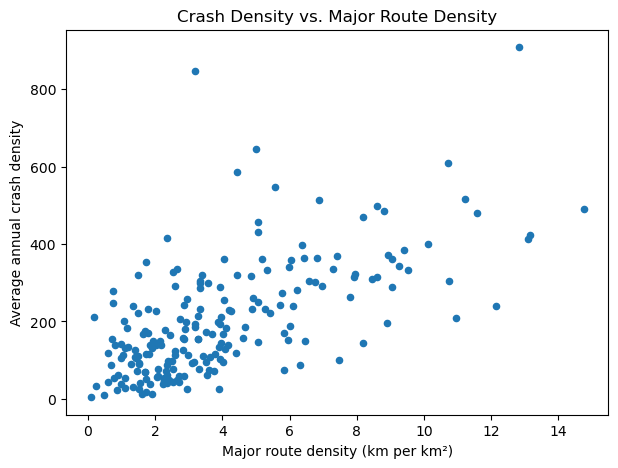

In [44]:
ax = route_tracts.plot(
    x="major_route_density_km_per_km2",
    y="avg_annual_crash_density",
    kind="scatter",
    figsize=(7, 5)
)

ax.set_xlabel("Major route density (km per km²)")
ax.set_ylabel("Average annual crash density")
ax.set_title("Crash Density vs. Major Route Density")

In [45]:
import numpy as np

race_cols = {
    "White": "white_alone_share",
    "Black": "black_alone_share",
    "Hispanic": "hispanic_share",
    "Asian": "asian_alone_share",
    "Two or More": "two_or_more_races_share",
    "Other": "other_race_share"
}

race_df = route_tracts[list(race_cols.values())].rename(
    columns={v: k for k, v in race_cols.items()}
)

route_tracts["dominant_demo_group"] = race_df.idxmax(axis=1)

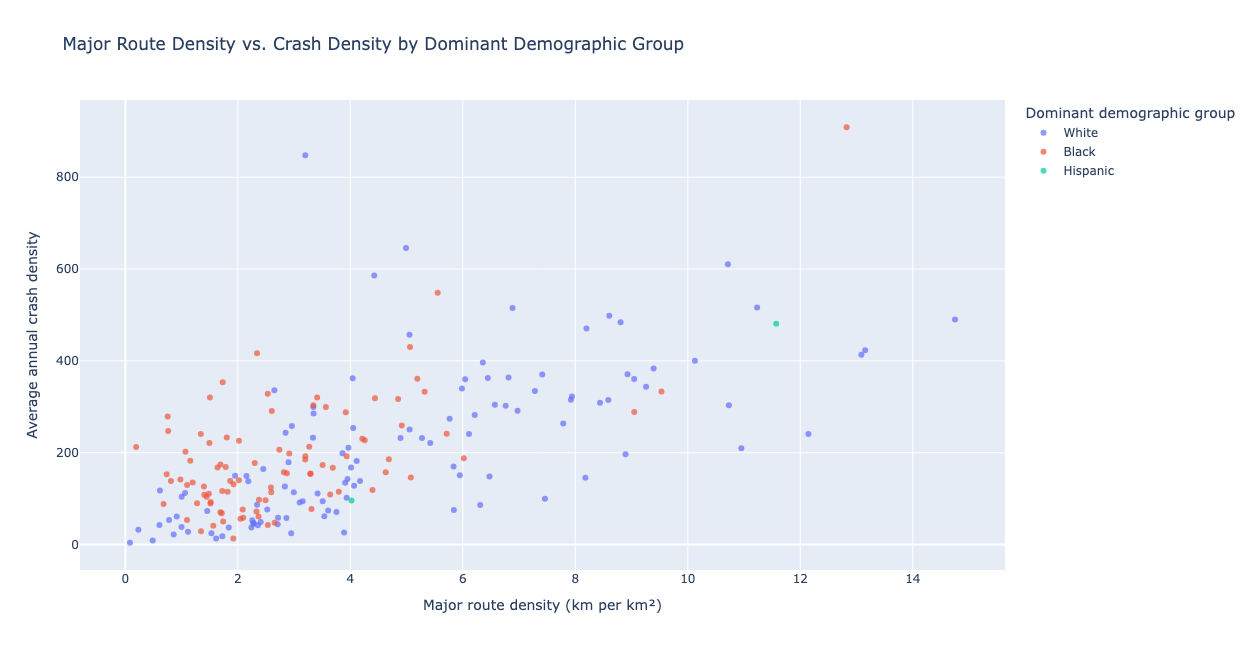

In [46]:
import plotly.express as px

fig = px.scatter(
    route_tracts,
    x="major_route_density_km_per_km2",
    y="avg_annual_crash_density",
    color="dominant_demo_group",
    hover_data=[
        "GEOID",
        "total_crashes",
        "major_route_length_km",
        "major_route_share",
        "white_alone_share",
        "black_alone_share",
        "hispanic_share",
        "asian_alone_share",
        "two_or_more_races_share",
        "other_race_share",
        "high_crash_route_tract"
    ],
    labels={
        "major_route_density_km_per_km2": "Major route density (km per km²)",
        "avg_annual_crash_density": "Average annual crash density",
        "dominant_demo_group": "Dominant demographic group"
    },
    title="Major Route Density vs. Crash Density by Dominant Demographic Group",
    opacity=0.7
)

fig.update_layout(width=950, height=650)
fig.show()

#### Major route density vs. crash density

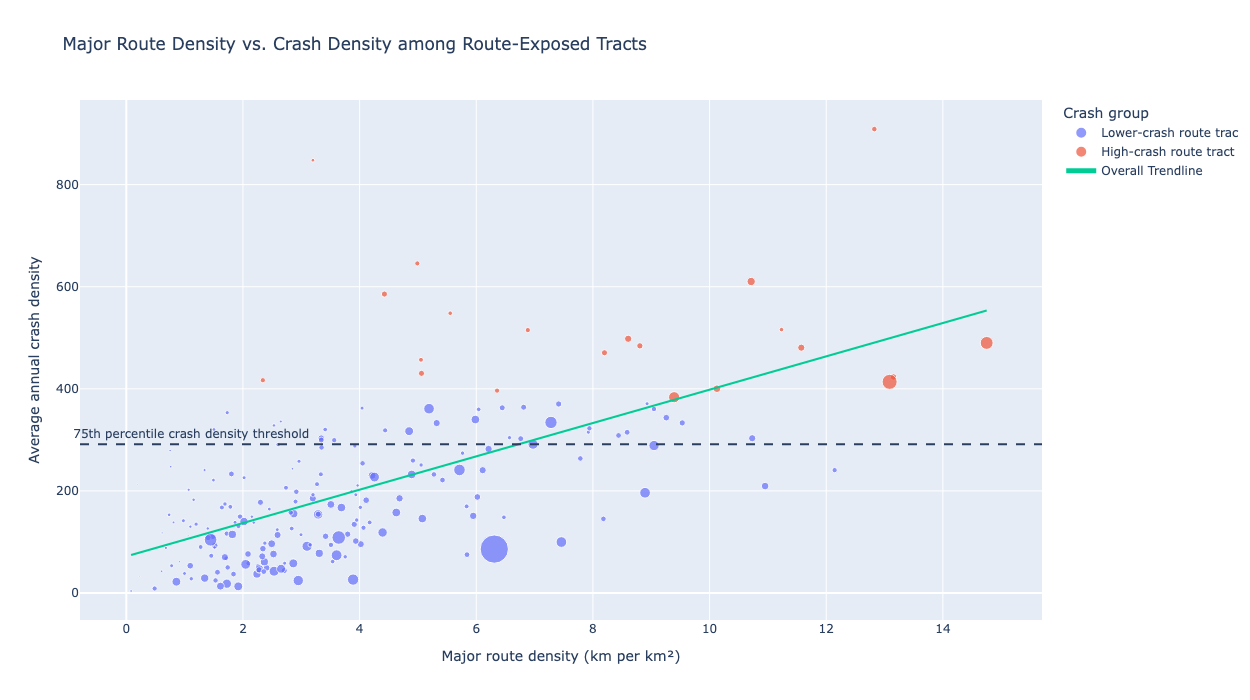

In [47]:
import plotly.express as px

# Create readable label for high-crash classification
route_tracts["route_crash_group"] = np.where(
    route_tracts["high_crash_route_tract"] == 1,
    "High-crash route tract",
    "Lower-crash route tract"
)

# 75th percentile threshold used to define high-crash tracts
q75 = route_tracts["avg_annual_crash_density"].quantile(0.75)

fig = px.scatter(
    route_tracts,
    x="major_route_density_km_per_km2",
    y="avg_annual_crash_density",
    color="route_crash_group",
    size="major_route_length_km",
    trendline="ols",
    trendline_scope="overall",
    opacity=0.70,
    hover_data={
        "GEOID": True,
        "total_crashes": True,
        "major_route_length_km": ":.2f",
        "major_route_share": ":.2f",
        "major_route_density_km_per_km2": ":.2f",
        "avg_annual_crash_density": ":.2f",
        "black_alone_share":":.2f",
        "hispanic_share":":.2f",
        "route_crash_group":True
    },
    labels={
        "major_route_density_km_per_km2": "Major route density (km per km²)",
        "avg_annual_crash_density": "Average annual crash density",
        "major_route_length_km": "Major route length (km)",
        "route_crash_group": "Crash group"
    },
    title="Major Route Density vs. Crash Density among Route-Exposed Tracts"
)

fig.add_hline(
    y=q75,
    line_dash="dash",
    annotation_text="75th percentile crash density threshold",
    annotation_position="top left"
)

fig.update_layout(
    width=1100,
    height=700
)

This figure introduces the relationship between major route exposure and crash concentration among route-exposed census tracts. Overall, average annual crash density increases as major route density increases, indicating a positive descriptive association between the two variables. The dashed horizontal line marks the 75th percentile of crash density, which is used to define high-crash route tracts.

High-crash route tracts appear across a broad range of moderate-to-high major route density values, rather than only in the tracts with the highest major route density. This suggests that major route density helps explain crash concentration, but additional roadway, traffic, corridor, or built-environment factors may also contribute.

heatmap - major route density vs. avg annual crash density


In [45]:
race_cols = [
    "white_alone_share",
    "black_alone_share",
    "hispanic_share",
    "asian_alone_share",
    "two_or_more_races_share",
    "other_race_share"
]

race_label_map = {
    "white_alone_share": "White alone share",
    "black_alone_share": "Black alone share",
    "hispanic_share": "Hispanic / Latino share",
    "asian_alone_share": "Asian alone share",
    "two_or_more_races_share": "Two or more races share",
    "other_race_share": "Other race share"
}

route_tracts_long = route_tracts.melt(
    id_vars=[
        "GEOID",
        "avg_annual_crash_density",
        "major_route_density_km_per_km2",
        "major_route_length_km",
        "major_route_share",
        "total_crashes",
        "high_crash_route_tract"
    ],
    value_vars=race_cols,
    var_name="demo_variable",
    value_name="demo_share"
)

route_tracts_long["demo_group"] = route_tracts_long["demo_variable"].map(race_label_map)
route_tracts_long["demo_share_pct"] = route_tracts_long["demo_share"] * 100

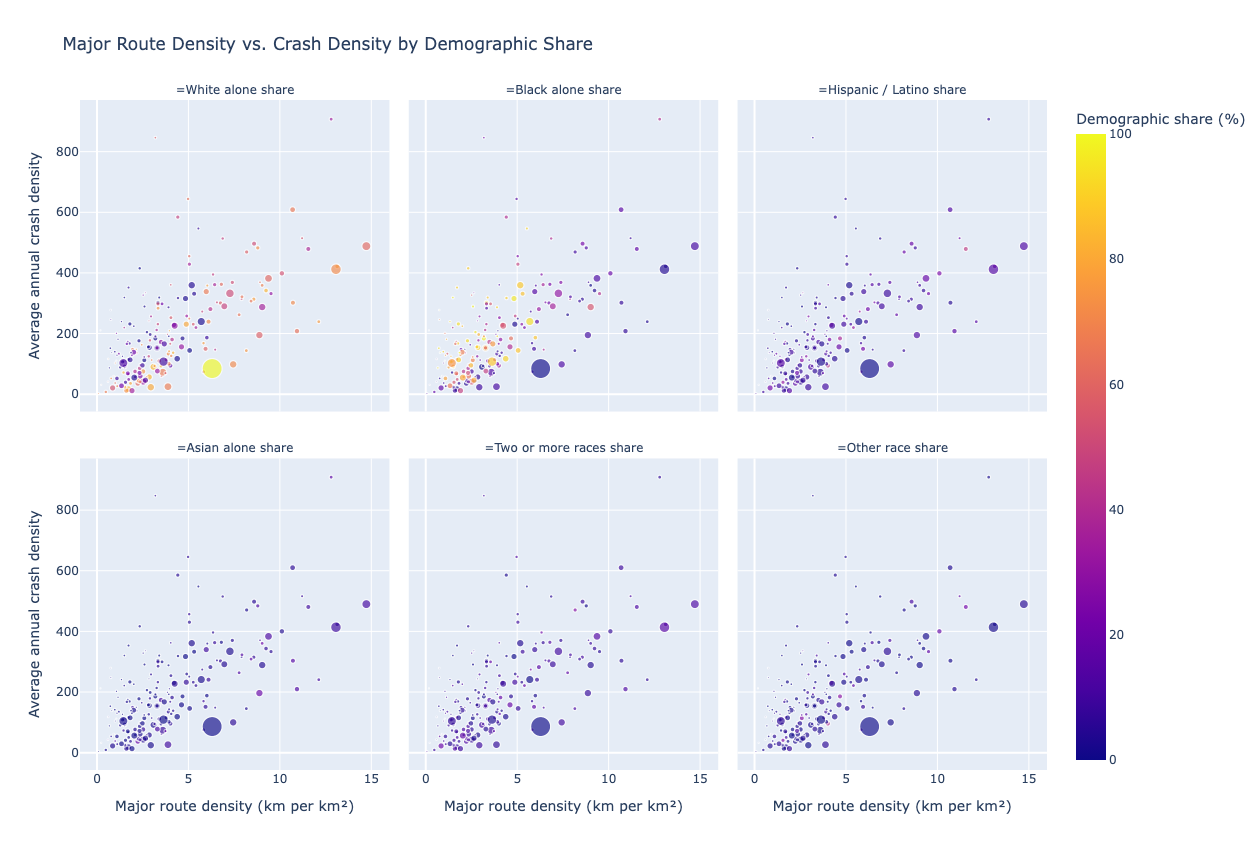

<Figure size 1500x1000 with 0 Axes>

In [48]:
import plotly.express as px

plt.figure(figsize=(15, 10))

fig = px.scatter(
    route_tracts_long,
    x="major_route_density_km_per_km2",
    y="avg_annual_crash_density",
    color="high",
    size="major_route_length_km",
    facet_col="demo_group",
    facet_col_wrap=3,
    opacity=0.65,
    hover_data={
        "GEOID": True,
        "total_crashes": True,
        "major_route_length_km": ":.2f",
        "major_route_share": ":.2f",
        "demo_share_pct": ":.1f",
        "high_crash_route_tract": True,
        "demo_variable": False
    },
    labels={
        "major_route_density_km_per_km2": "Major route density (km per km²)",
        "avg_annual_crash_density": "Average annual crash density",
        "demo_share_pct": "Demographic share (%)",
        "major_route_length_km": "Major route length (km)",
        "demo_group": ""
    },
    title="Major Route Density vs. Crash Density by Demographic Share"
)

fig.update_layout(
    width=1200,
    height=850
)

fig.show()

Each point represents one of the 205 route-exposed census tracts. The same set of tracts is shown in each panel. Color intensity represents the demographic share shown in that panel, with brighter points indicating a higher population share for that group. Point size represents the total major route length within the tract.

To further explore whether tract-level demographic composition appears differently distributed across the route-density and crash-density space, the next figure visualizes the same route-exposed tracts across six demographic share variables. Each panel uses the same x- and y-axes, while color intensity represents the demographic share shown in that panel.

High crash density in higher-Black-share tracts may not be explained by major route density alone, and should not be interpreted as caused by Black residents or racial identity itself.